<a href="https://colab.research.google.com/github/lilyzhengliwang/econ3916-midterm-project-econometric-foundation/blob/main/ECON3916_Midterm_Project_Econometric_Foundation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [3]:
SOURCE_URL = "https://collegescorecard.ed.gov/data/"       # the page or file you downloaded from
DOWNLOAD_DATE = "2026-10-26"    # YYYY-MM-DD
FILE_NAME = "Most-Recent-Cohorts-Institution.csv"        # the file as saved in your repository's data/ folder

In [4]:
# loading the full csv
full_df = pd.read_csv('/content/drive/MyDrive/Most-Recent-Cohorts-Institution.csv')
full_df.shape

/tmp/ipykernel_28988/1074688746.py:2: DtypeWarning: Columns (9,1433,1447,1475,1537,1540,1542,1606,1608,1614,1615,1619,1620,1621,1622,1623,1624,1625,1626,1627,1628,1629,1725,1726,1727,1728,1729,1743,1815,1816,1817,1818,1823,1824,1830,1831,1879,1880,1881,1882,1883,1884,1885,1886,1887,1888,1889,1890,1891,1892,1893,1894,1895,1896,1897,1898,1909,1910,1911,1912,1913,1957,1958,1959,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1983,1984,2376,2377,2403,2404,2495,2496,2497,2498,2499,2500,2501,2502,2503,2504,2505,2506,2507,2508,2509,2510,2511,2512,2513,2514,2515,2516,2517,2518,2519,2520,2521,2522,2523,2524,2525,2526,2527,2528,2529,2530,3215,3231,3235,3236) have mixed types. Specify dtype option on import or set low_memory=False.
  full_df = pd.read_csv('/content/drive/MyDrive/Most-Recent-Cohorts-Institution.csv')


(6278, 3379)

In [5]:
# only keeping columns that we need and creating a new df
columns = ['UNITID', 'INSTNM', 'STABBR', 'CONTROL', 'PREDDEG', 'CURROPER',
           'MD_EARN_WNE_P10', 'NPT4_PUB', 'NPT4_PRIV', 'INEXPFTE', 'PCTPELL',
           'ADM_RATE', 'SAT_AVG', 'UGDS']

df = full_df[columns]

df.head()

,UNITID,INSTNM,STABBR,CONTROL,PREDDEG,CURROPER,MD_EARN_WNE_P10,NPT4_PUB,NPT4_PRIV,INEXPFTE,PCTPELL,ADM_RATE,SAT_AVG,UGDS
0,100654,Alabama A & M University,AL,1,3,1,41266,18255.0,NaN,7254.0,0.6419,0.5795,938.0,6124.0
1,100663,University of Alabama at Birmingham,AL,1,3,1,59631,15630.0,NaN,17855.0,0.3885,0.8818,1258.0,11635.0
2,100690,Amridge University,AL,2,3,1,40519,NaN,NaN,4918.0,0.4568,NaN,NaN,241.0
3,100706,University of Alabama in Huntsville,AL,1,3,1,72098,22758.0,NaN,9877.0,0.2781,0.6857,1319.0,6591.0
4,100724,Alabama State University,AL,1,3,1,40585,9775.0,NaN,10723.0,0.7197,0.9755,976.0,3477.0


In [6]:
### saving the file once for record-keeping and for Github

#from google.colab import files

#df.to_csv('Most-Recent-Cohorts-Institution-modified.csv', index=False)
#files.download('Most-Recent-Cohorts-Institution-modified.csv')

In [7]:
# loading in historical data for net price & institutional spend to merge with df

historical_df = pd.read_csv('/content/drive/MyDrive/MERGED2010_11_PP.csv')

/tmp/ipykernel_28988/3113217731.py:3: DtypeWarning: Columns (1,6,1170,1171,1173,1174,1175,1177,1179,1180,1183,1184,1186,1187,1196,1209,1222,1223,1225,1226,1235,1236,1238,1239,1248,1249,1251,1252,1261,1262,1264,1265,1274,1275,1277,1278,1279,1287,1288,1290,1291,1292,1326,1327,1329,1330,1331,1335,1339,1340,1342,1343,1344,1348,1407,1408,1409,1410,1411,1412,1413,1414,1415,1416,1420,1426,1427,1431,1432,1461,1475,1487,1488,1489,1490,1491,1492,1493,1494,1495,1496,1497,1498,1499,1500,1501,1502,1503,1506,1509,1510,1511,1512,1513,1514,1515,1516,1517,1520,1521,1522,1523,1524,1525,1526,1527,1528,1529,1530,1532,1534,1535,1537,1538,1539,1540,1541,1542,1546,1547,1559,1560,1561,1604,1605,1606,1609,1610,1611,1613,1614,1615,1616,1688,1689,1690,1691,1692,1703,1704,1705,1706,1707,1729,1909,1910,1911,1912,1913) have mixed types. Specify dtype option on import or set low_memory=False.
  historical_df = pd.read_csv('/content/drive/MyDrive/MERGED2010_11_PP.csv')


In [8]:
historical_df.shape

(7470, 3379)

In [9]:
# merging current dataset with historical net price & institutional spend

cols = ['UNITID', 'PREDDEG', 'CONTROL', 'NPT4_PUB', 'NPT4_PRIV', 'INEXPFTE',
        'ADM_RATE', 'SAT_AVG', 'PCTPELL', 'UGDS']

hist_2010 = (historical_df[cols]
             .add_suffix('_2010')
             .rename(columns={'UNITID_2010': 'UNITID'}))

df = df.merge(hist_2010, on='UNITID', how='left',
              validate='one_to_one', indicator=True)

# Match-rate check
print(df['_merge'].value_counts())
print(f"Matched: {(df['_merge'] == 'both').mean():.1%}")
df = df.drop(columns='_merge')

_merge
both          4765
left_only     1513
right_only       0
Name: count, dtype: int64
Matched: 75.9%


In [10]:
### saving the 2010 file once for record-keeping and for Github

#from google.colab import files

#df.to_csv('MERGED2010_11_PP.csv', index=False)
#files.download('MERGED2010_11_PP.csv')

In [11]:
# count privacy suppressed earning values
df['earn_suppressed'] = df['MD_EARN_WNE_P10'].eq('PS')
print('PS count:', df['earn_suppressed'].sum())
df['MD_EARN_WNE_P10'] = pd.to_numeric(df['MD_EARN_WNE_P10'], errors='coerce')

df['net_price']      = df['NPT4_PUB'].fillna(df['NPT4_PRIV'])
df['net_price_2010'] = df['NPT4_PUB_2010'].fillna(df['NPT4_PRIV_2010'])
df['in_2010_file']   = df['PREDDEG_2010'].notna()

cols = ['MD_EARN_WNE_P10', 'net_price_2010', 'INEXPFTE_2010',
        'PCTPELL_2010', 'ADM_RATE_2010', 'SAT_AVG_2010']

def miss_table(d):
    return pd.DataFrame({'n_missing': d[cols].isna().sum(),
                         'pct_missing': (d[cols].isna().mean() * 100).round(1)})
# print count and percent missing from historical data on schools that primarily
# give out bachelor's (PREDDEG_2010 == 3)
print(df['in_2010_file'].value_counts())
bach = df[df['PREDDEG_2010'] == 3]
print(len(bach)); print(miss_table(bach))

PS count: 623
in_2010_file
True     4765
False    1513
Name: count, dtype: int64
1727
                 n_missing  pct_missing
MD_EARN_WNE_P10         53          3.1
net_price_2010         111          6.4
INEXPFTE_2010           21          1.2
PCTPELL_2010            14          0.8
ADM_RATE_2010          258         14.9
SAT_AVG_2010           457         26.5


In [12]:
# what is missing inside the full merged df
#print(df.isna().sum(), df.isna().mean())

### Columns Glossary

| Column | Meaning |
|--------|---------|
|UNITID  |The institution's unique ID; row identifier|
|ISTNM| Institution name|
|STABBR| State postal abbreviation|
|CONTROL| 1 = public, 2 = private nonprofit, 3 = private for-profit|
|PREDDEG| The degree level the school mostly awards: 0 = not classified, 1 = certificate, 2 = associate, 3 = bachelor's, 4 = graduate|
|CURROPER| Whether the school is currently operating; 1 = yes, 0 = no|
|MD_EARN_WNE_P10| Median earnings of students who are working and not enrolled 10 years after they entered school; covers federal-aid recipients only|
|NPT4_PUB| Average net price for aid recipients who went to public schools|
|NPT4_PUB_2010| Average 2010 net price for aid recipients who went to public schools|
|NPT4_PRIV| Average net price for aid recipients who went to private schools (nonprofit and for profit)|
|NPT4_PRIV_2010| Average 2010 net price for aid recipients who went to private schools (nonprofit and for profit)|
|INEXPFTE| Instructional spending per full-time-equivalent student|
|INEXPFTE_2010| 2010 instructional spending per full-time-equivalent student|
|PCTPELL| Share of undergrads receiving Pell grants|
|ADM_RATE| Admission rate|
|ADM_RATE_2010| Admission rate in 2010|
|SAT_AVG| Average SAT score of admitted students|
|SAT_AVG_2010| Average SAT score of admitted students in 2010|
|UGDS| Number of undergraduates seeking degree|


**Who collected it, for what purpose, what is missing and why?**

The data was collected by the US Department of Education, both for policymakers and researchers as well for prospective students and families to compare colleges. In the most recent file containing institutional data, our earnings cohort entered in academic year (AY) 2009-2010 and 2010-11, so we will be using historical data from 2010-2011 for metrics such as net price, institutional spend, etc. Overall, it increases transparency and gives families data to compare factors like cost, financial aid, post graduation outcomes, and more to make more informed decisions. There are blanks in median earnings post-10 years because no earnings data was reported; there are also values that are not blank but marked as "PS" for privacy suppressed, which are typically for small cohorts. There are missing values in average net price for public and private schools because they are separate columns and each schools will only have one of the two columns filled out because it is either public or private. For the remaining missing net price data, it was either not reported, or it does not enroll aid recipients. There are some reporting gaps in instructional spending but it is nearly complete. A large percentage of schools are missing admission rate, potentially because open admission schools do not report admission rate. Most schools are missing SAT average score, either bcause they are test optional or did not report. Finally, there are some reporting gaps in number of undergrads seeking degrees.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

**Question**: Among US colleges that mainly award bachelor's degrees, how much of the variation in median earnings of federal-aid recipients 10 years after entry in the 2009-2011 cohort is associated with net price after accounting for selectivity and share of undergrads receiving Pell grant?


**Why it matters and to whom:**
* Students and families - they are deciding whether a higher price or a better funded schools pays off
* State legislators and boards - they set tuition and student funding
* Federal regulators - they can hold schools accountable for outcomes


**Measurement Decisions**
* Earnings - `MD_EARN_WNE_P10` only covers students who received federal aid that are working and not enrolled, and the number is a median per school, not measured at an individual's level. The earnings cohort entered in AY2009-10 and AY2010-11 (pooled) and was measured in 2020-21 in 2022 dollars (see CollegeScorecardDataDictionary.xlsx)
* Timing - the earnings cohort entered about a decade ago, but net price, institutional spend, and other metrics are all recent, so we are using metrics from 2010-2011 to reconcile timing differences
* Admission rate - only exists where there is selective admission


**What Is Missing**
* Earnings - some are missing because of lack of reporting, others are not revealed because of "PS" or privacy suppression due to small cohorts
* Admission Rate - a missing admission rate most likely due to a school being open-admission (MNAR)
* Net price - NPT4_PUB and NPT4_PRIV are empty by design because a school is either private or public, so one of these will be blank. The remaining blanks are either because the school has no aid recipients or did not report
* SAT Average - there are test optional schools and open admission schools that don't report, meaning that schools that have SAT average score are typically more competitive (MNAR)
* Instructional spending - mostly due to reporting gaps (MCAR)



In [13]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "institution (UNITID)"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "MD_EARN_WNE_P10"     # your dependent variable's column name
MAIN_X = "net_price_2010"      # your main explanatory variable's column name
CONTROLS = ["PCTPELL_2010", "ADM_RATE_2010", "CONTROL_2010"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 6,278   Columns: 27   One row is: institution (UNITID)

Missing values per column:
MD_EARN_WNE_P10     985
net_price_2010     3338
PCTPELL_2010       1876
ADM_RATE_2010      4482
CONTROL_2010       1513

Skew of MD_EARN_WNE_P10: 1.22 (above about 1, consider a log)


In [14]:
# adjusting 2009-2010 dollars to 2022 dollars

cpi = (pd.read_csv('/content/drive/MyDrive/CPIAUCNS.csv', parse_dates=['observation_date'])
         .set_index('observation_date')['CPIAUCNS'])

base_2022 = cpi['2022-01-01':'2022-12-31'].mean()  # target is 2022 dollars
ay_2009_10 = cpi['2009-07-01':'2010-06-30'].mean()  # academic year 2009-10
cpi_factor = base_2022 / ay_2009_10
print(f"CPI factor, AY2009-10 -> 2022 dollars: {cpi_factor:.3f}")

df['net_price_2010_2022usd'] = df['net_price_2010'] * cpi_factor
df['INEXPFTE_2010_2022usd']  = df['INEXPFTE_2010'] * cpi_factor

CPI factor, AY2009-10 -> 2022 dollars: 1.350


In [15]:
# summary statistics table


analysis_vars = ["MD_EARN_WNE_P10", "net_price_2010", "PCTPELL_2010", "ADM_RATE_2010"]

sample = bach.dropna(subset=analysis_vars).copy()
sample["net_price_2022"] = sample["net_price_2010"] * cpi_factor     # new
sample["pell_pct"] = sample["PCTPELL_2010"] * 100
sample["adm_pct"]  = sample["ADM_RATE_2010"] * 100

print("Bachelor's-focused schools in 2010 file:", len(bach), "  in the sample:", len(sample))

cols = ["MD_EARN_WNE_P10", "net_price_2022",                          # changed
        "pell_pct", "adm_pct", "UGDS_2010", "SAT_AVG_2010"]

table1 = sample[cols].describe().T[["mean", "50%", "std", "min", "max", "count"]]
table1.columns = ["mean", "median", "std", "min", "max", "N"]
table1.index = [
    "Median earnings, 10 yrs after entry ($, 2022 dollars)",
    "Net price, AY2009-10 ($ per year, 2022 dollars)",                # changed label
    "Pell share of undergraduates, AY2009-10 (%)",
    "Admission rate, Fall 2010 (%)",
    "Degree-seeking undergraduates, Fall 2010 (students)",
    "Average SAT score, Fall 2010 (points)",]
table1.round(1)

Bachelor's-focused schools in 2010 file: 1727   in the sample: 1422


,mean,median,std,min,max,N
"Median earnings, 10 yrs after entry ($, 2022 dollars)",62191.9,59628.0,17101.2,19092.0,166642.0,1422.0
"Net price, AY2009-10 ($ per year, 2022 dollars)",23315.9,22493.8,9566.0,-27934.8,60695.5,1422.0
"Pell share of undergraduates, AY2009-10 (%)",34.1,31.0,16.6,0.0,100.0,1422.0
"Admission rate, Fall 2010 (%)",64.8,66.9,19.2,7.2,100.0,1422.0
"Degree-seeking undergraduates, Fall 2010 (students)",5246.1,2419.0,6855.7,36.0,56977.0,1422.0
"Average SAT score, Fall 2010 (points)",1067.9,1049.5,128.0,715.0,1528.0,1252.0


In [16]:
# funnel
hist_bach = historical_df[historical_df['PREDDEG'] == 3]
rows = [("Bachelor's-focused in the 2010-11 file", len(hist_bach)),
        ("Not in the current file", len(bach) - len(hist_bach))]
cur = bach
for label, c in [("No earnings", "MD_EARN_WNE_P10"), ("No net price", "net_price_2010"),
                 ("No Pell share", "PCTPELL_2010"), ("No admission rate", "ADM_RATE_2010")]:
    n0 = len(cur); cur = cur[cur[c].notna()]; rows.append((label, len(cur) - n0))
rows.append(("Schools in the sample", len(cur)))
funnel = pd.DataFrame(rows, columns=["Step", "Schools"]); print(funnel)
assert len(cur) == len(sample)

bm = bach.assign(earn_miss=bach["MD_EARN_WNE_P10"].isna(), adm_miss=bach["ADM_RATE_2010"].isna(),
                 size_q=pd.qcut(bach["UGDS_2010"], 4, duplicates="drop"),
                 sector=bach["CONTROL_2010"].map({1: "Public", 2: "Private nonprofit", 3: "Private for-profit"}))
print(bm.groupby("sector")[["earn_miss", "adm_miss"]].mean().round(3))
print(bm.groupby("size_q", observed=True)["earn_miss"].mean().round(3))
if "OPENADMP" in historical_df.columns:    # open-admission flag, if the 2010 file has it
    oa = historical_df.loc[historical_df["PREDDEG"] == 3, ["OPENADMP", "ADM_RATE"]]
    print(pd.crosstab(oa["OPENADMP"].fillna(-1), oa["ADM_RATE"].isna()))

sample["OPEID6"] = sample["UNITID"].map(full_df.set_index("UNITID")["OPEID6"])
g = sample.groupby("OPEID6").size()
print("Institutions:", len(g), "| multi-campus:", (g > 1).sum(), "| rows in them:", g[g > 1].sum())

                                     Step  Schools
0  Bachelor's-focused in the 2010-11 file     2102
1                 Not in the current file     -375
2                             No earnings      -53
3                            No net price      -89
4                           No Pell share        0
5                       No admission rate     -163
6                   Schools in the sample     1422
                    earn_miss  adm_miss
sector                                 
Private for-profit      0.014     0.522
Private nonprofit       0.043     0.142
Public                  0.009     0.119
size_q
(7.999, 978.0]       0.100
(978.0, 2097.0]      0.005
(2097.0, 5456.0]     0.009
(5456.0, 56977.0]    0.000
Name: earn_miss, dtype: float64
ADM_RATE  False  True 
OPENADMP              
-1.0          0     95
 1.0          0    327
 2.0       1648     32
Institutions: 1376 | multi-campus: 20 | rows in them: 66


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Your answers here.*
1.
* CONTROL_2010 (public/private/for-profit) - no, it is a cofounder
* ADM_RATE-2010 - no for the most part, because admission rate comes from applicate demand and how many people the school accepts; it is possible that knowing the price could change who applies, but mostly it is a cofounder
* PCTPELL_2010 - mostly no; Pell grants lower net price instead of the reverse
* INEXPFTE_2010 (institutional spend) - originally included and yes potentially, because tuition revenue funds instruction, so this would be on the path from price to earnings - I have dropped it.

2. The variables are aligned on timing for the most part. The earnings are of the AY2009-10 and 2010-11 cohorts measured in 2020-21 in 2022 dollars. The net price, pell share, and degree level are AY2009-10, and the admission rate is Fall 2010. We have converted nominal net price to 2022 dollars using downloaded CPI data from FRED.

3. This is not a policy question.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

In [17]:
sample = bach.dropna(subset=["MD_EARN_WNE_P10", "net_price_2010","PCTPELL_2010", "ADM_RATE_2010"]).copy()
sample["earn_k"] = sample["MD_EARN_WNE_P10"] / 1000
sample["log_earn"] = np.log(sample["MD_EARN_WNE_P10"])
sample["net_price_k"] = sample["net_price_2010"] * cpi_factor / 1000   # $1,000s, 2022 dollars
sample["adm_pct"] = sample["ADM_RATE_2010"] * 100
sample["control"] = sample["CONTROL_2010"].map({1: "Public", 2: "Private nonprofit", 3: "Private for-profit"})

Is the Outcome Skewed?


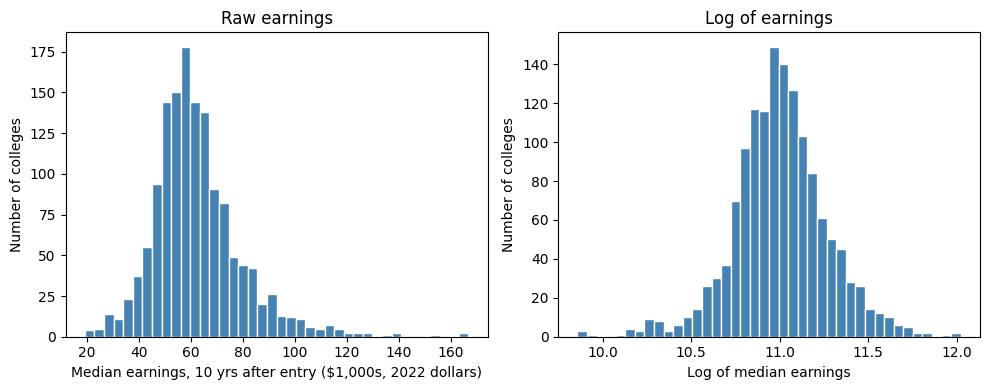

Skew raw: 1.23  Skew log: -0.14
Mean vs median earnings ($): 62192 59628


In [18]:
# skewness
print("Is the Outcome Skewed?")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(sample["earn_k"], bins=40, color="steelblue", edgecolor="white")
ax[0].set(xlabel="Median earnings, 10 yrs after entry ($1,000s, 2022 dollars)",
          ylabel="Number of colleges", title="Raw earnings")
ax[1].hist(sample["log_earn"], bins=40, color="steelblue", edgecolor="white")
ax[1].set(xlabel="Log of median earnings", ylabel="Number of colleges", title="Log of earnings")
plt.tight_layout(); plt.show()

print("Skew raw:", round(sample["MD_EARN_WNE_P10"].skew(), 2), " Skew log:", round(sample["log_earn"].skew(), 2))
print("Mean vs median earnings ($):", round(sample["MD_EARN_WNE_P10"].mean()), round(sample["MD_EARN_WNE_P10"].median()))

Caption: earnings are right skewed with a skew of 1.23 before log transformation, driven by few high earning schools. After the log transformation, the distribution is roughly symmetric with a skew of -0.14.

Net Price Against Log Earnings Split by Control Type


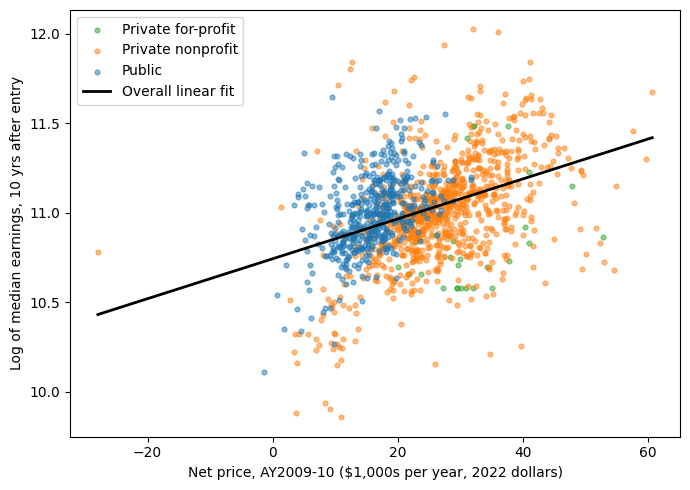

Overall corr: 0.4
control
Private for-profit    0.26
Private nonprofit     0.50
Public                0.46
dtype: float64


/tmp/ipykernel_28988/1330381090.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(sample.groupby("control").apply(lambda g: round(g["net_price_k"].corr(g["log_earn"]), 2)))


In [19]:
# net price vs earnings, split by control type

print('Net Price Against Log Earnings Split by Control Type')

colors = {"Public": "tab:blue", "Private nonprofit": "tab:orange", "Private for-profit": "tab:green"}
fig, ax = plt.subplots(figsize=(7, 5))
for name, g in sample.groupby("control"):
    ax.scatter(g["net_price_k"], g["log_earn"], s=12, alpha=0.5, color=colors[name], label=name)
m, b0 = np.polyfit(sample["net_price_k"], sample["log_earn"], 1)
xs = np.linspace(sample["net_price_k"].min(), sample["net_price_k"].max(), 100)
ax.plot(xs, b0 + m * xs, color="black", lw=2, label="Overall linear fit")
ax.set(xlabel="Net price, AY2009-10 ($1,000s per year, 2022 dollars)",
       ylabel="Log of median earnings, 10 yrs after entry", title="")
ax.legend(); plt.tight_layout(); plt.show()

print("Overall corr:", round(sample["net_price_k"].corr(sample["log_earn"]), 2))
print(sample.groupby("control").apply(lambda g: round(g["net_price_k"].corr(g["log_earn"]), 2)))

Caption: The overall slope is positive, but the correlation is weak to moderate. The spread of private non-profit schools is larger than the spread of public schools. Schools with higher net prices tend to have only slightly higher median earnings overall.

/tmp/ipykernel_28988/3184654809.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=["Most selective", "2nd", "3rd", "Least selective"])


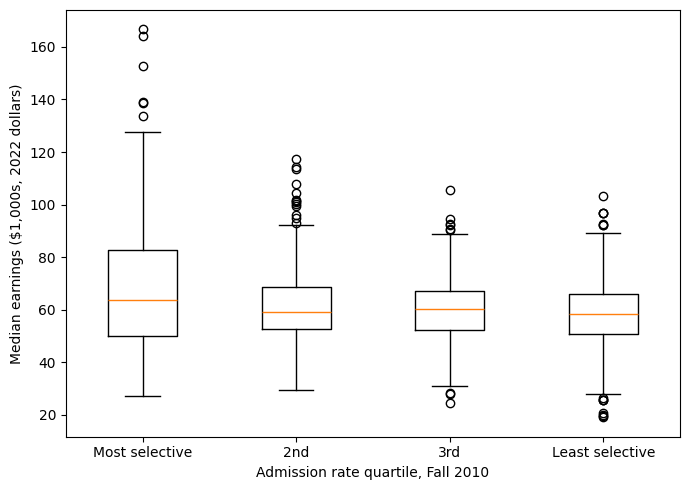

                 earn_k  net_price_k
adm_group                           
Most selective     63.8         22.4
2nd                59.2         22.7
3rd                60.3         23.6
Least selective    58.3         20.8


In [20]:
#Selectivity (admissions rate) and median earnings

sample["adm_group"] = pd.qcut(sample["adm_pct"], 4,
                              labels=["Most selective", "2nd", "3rd", "Least selective"])
groups = [g["earn_k"].values for _, g in sample.groupby("adm_group", observed=True)]
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot(groups, labels=["Most selective", "2nd", "3rd", "Least selective"])
ax.set(xlabel="Admission rate quartile, Fall 2010", ylabel="Median earnings ($1,000s, 2022 dollars)")
plt.tight_layout(); plt.show()

print(sample.groupby("adm_group", observed=True)[["earn_k", "net_price_k"]].median().round(1))

Median earnings are somewhat higher at the most selective schools at \$63.8k than the least selective quartile at \$58.3k, but the gap is very small. The median net price also does not differ by much between the quartiles, except for the least selective quartile being roughly \$2-3k lower. However, the most selective quartile of schools shows a larger interquartile range running from roughly \$50k to a little over \$80k, whereas the other quartiles seem to have interquartile ranges around \$15k.

In [21]:
print(sample[["adm_pct", "net_price_k", "log_earn"]].corr().round(2))
print(sample["adm_pct"].quantile([0.25, 0.5, 0.75]).round(1))  #label the x-axis groups
print(sample.nlargest(5, "earn_k")[["INSTNM", "control", "adm_pct", "earn_k"]])  #top outliers?

             adm_pct  net_price_k  log_earn
adm_pct         1.00        -0.06     -0.24
net_price_k    -0.06         1.00      0.40
log_earn       -0.24         0.40      1.00
0.25    53.1
0.50    66.9
0.75    78.2
Name: adm_pct, dtype: float64
                                      INSTNM            control  adm_pct  \
184       California Institute of Technology  Private nonprofit    12.55   
288                      Harvey Mudd College  Private nonprofit    23.44   
1384   Massachusetts Institute of Technology  Private nonprofit    10.08   
1331                          Babson College  Private nonprofit    39.55   
4155  Franklin W Olin College of Engineering  Private nonprofit    29.98   

       earn_k  
184   166.642  
288   164.248  
1384  152.553  
1331  138.950  
4155  138.832  


## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [22]:
# fit models
sample["pell_pct"] = sample["PCTPELL_2010"] * 100

m1 = smf.ols("log_earn ~ net_price_k", data=sample).fit()
m2 = smf.ols("log_earn ~ net_price_k + adm_pct + pell_pct + C(control, Treatment('Public'))",
             data=sample).fit()

In [23]:
# robust SE and CI
f2 = "log_earn ~ net_price_k + adm_pct + pell_pct + C(control, Treatment('Public'))"
m2r = smf.ols(f2, sample).fit(cov_type="HC3")
models = {"(1) Simple": m1, "(2) w/ Controls": m2, "(3) Robust SE (HC3)": m2r}
lo_r, hi_r = m2r.conf_int().loc["net_price_k"]
print(f"Robust 95% CI: [{100*(np.exp(lo_r)-1):.2f}%, {100*(np.exp(hi_r)-1):.2f}%]")

Robust 95% CI: [0.29%, 0.71%]


In [24]:
# format regression table

print("*Note: an asterisk * next to a coefficient means p<0.05")

labels = {"Intercept": "Constant", "net_price_k": "Net price ($1,000s, 2022 dollars)",
    "adm_pct": "Admission rate (percentage points)","pell_pct": "Pell share (percentage points)",
    "C(control, Treatment('Public'))[T.Private nonprofit]": "Private nonprofit (vs. public)",
    "C(control, Treatment('Public'))[T.Private for-profit]": "Private for-profit (vs. public)",}
models = {"(1) Simple": m1, "(2) w/ Controls": m2, "(3) Controls, HC3 robust SE": m2r}
stars = lambda p: "*" if p < .05 else ""

rows = []
for term, label in labels.items():
    coef_row, se_row = {"": label}, {"": ""}
    for name, m in models.items():
        if term in m.params.index:
            coef_row[name] = f"{m.params[term]:.4f}{stars(m.pvalues[term])}"
            se_row[name]   = f"({m.bse[term]:.4f})"
        else:
            coef_row[name] = se_row[name] = ""
    rows += [coef_row, se_row]
rows += [{"": "N", **{n: f"{int(m.nobs):,}" for n, m in models.items()}},
         {"": "R-squared", **{n: f"{m.rsquared:.3f}" for n, m in models.items()}}]

table2 = pd.DataFrame(rows).set_index("")
table2

*Note: an asterisk * next to a coefficient means p<0.05


,(1) Simple,(2) w/ Controls,"(3) Controls, HC3 robust SE"
,,,
Constant,10.7425*,11.4548*,11.4548*
,(0.0172),(0.0276),(0.0367)
"Net price ($1,000s, 2022 dollars)",0.0111*,0.0050*,0.0050*
,(0.0007),(0.0007),(0.0011)
Admission rate (percentage points),,-0.0029*,-0.0029*
,,(0.0003),(0.0003)
Pell share (percentage points),,-0.0099*,-0.0099*
,,(0.0003),(0.0004)
Private nonprofit (vs. public),,-0.0649*,-0.0649*


In [25]:
b  = m2.params["net_price_k"]
lo, hi = m2.conf_int().loc["net_price_k"]
med = sample["MD_EARN_WNE_P10"].median()
print(f"Net price: {100*(np.exp(b)-1):.2f}% per +$1,000 | 95% CI "
      f"[{100*(np.exp(lo)-1):.2f}%, {100*(np.exp(hi)-1):.2f}%] | p = {m2.pvalues['net_price_k']:.3f}")
print(f"  ~ ${med*(np.exp(b)-1):,.0f} at the median earnings of ${med:,.0f}")

bp = m2.params["pell_pct"]
print(f"Pell share: {100*(np.exp(10*bp)-1):.2f}% per +10 pp | p = {m2.pvalues['pell_pct']:.3f}")
print("Net price coef, model 1 -> 2:", round(m1.params['net_price_k'], 4), "->", round(b, 4))

Net price: 0.50% per +$1,000 | 95% CI [0.35%, 0.64%] | p = 0.000
  ~ $297 at the median earnings of $59,628
Pell share: -9.40% per +10 pp | p = 0.000
Net price coef, model 1 -> 2: 0.0111 -> 0.005


For the net price coefficient, comparing schools of the same sector, selectivity and Pell grant share, a school with $1,000 higher net price (2022 dollars) has about 0.5% higher median earnings with a 95% CI (robust) of [0.3%, 0.7%]. The net price coefficient almost halved from the simple model at 0.01 to 0.005 to the model with controls. The estimate is statistically significant with a p-value of 0. For the pell share, each 10 percntage point increase in pell share is associated with -9.4% lower earnings holding other variables constant, with a p-value of 0.

### Controls

|Control | Role| What would make it a bad control|
|---|---|---|
|Sector (`control`)| blocks a cofounding path, since sector affects both net price and earnings| if somehow sector was dependent on net price and revenue model|
|Admission rate| adds precision by explaining earnings variation unrelated to price| If price changes who applies, then admission rate would be a partial outcome of price which would put it on the path|
|Pell share| blocks a cofounding path, since student income affects earnings and affects net price| If high price discourages low income students from enrolling and pell share is also caused by price|

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

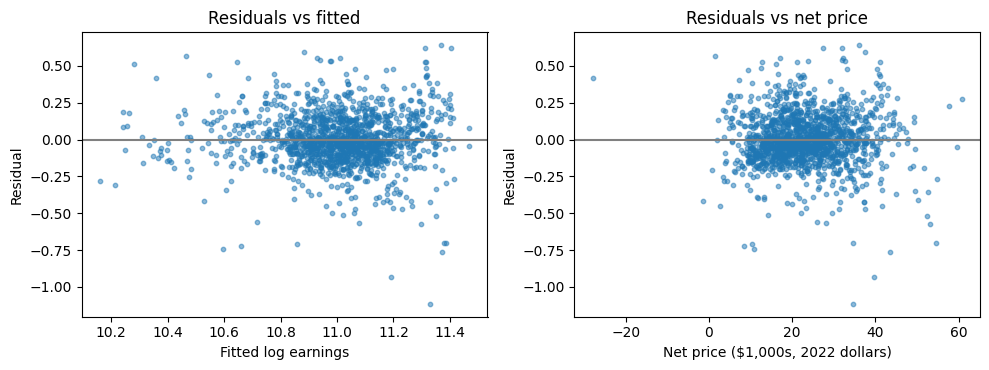

Breusch-Pagan p = 0.0000
                                                    classical SE  robust SE
Intercept                                                 0.0276     0.0367
C(control, Treatment('Public'))[T.Private for-p...        0.0368     0.0544
C(control, Treatment('Public'))[T.Private nonpr...        0.0130     0.0147
net_price_k                                               0.0007     0.0011
adm_pct                                                   0.0003     0.0003
pell_pct                                                  0.0003     0.0004
VIF: {"C(control, Treatment('Public'))[T.Private for-profit]": np.float64(1.23), "C(control, Treatment('Public'))[T.Private nonprofit]": np.float64(1.72), 'net_price_k': np.float64(2.12), 'adm_pct': np.float64(1.02), 'pell_pct': np.float64(1.46)}
Largest Cook's distance:
Chamberlain University-Florida     0.069
Chamberlain University-Illinois    0.059
Chamberlain University-Ohio        0.057
Net price coef: all schools 0.005 | without top 

In [26]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Residuals vs fitted, and vs the main predictor
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(m2.fittedvalues, m2.resid, s=10, alpha=0.5); ax[0].axhline(0, color="grey")
ax[0].set(xlabel="Fitted log earnings", ylabel="Residual", title="Residuals vs fitted")
ax[1].scatter(sample["net_price_k"], m2.resid, s=10, alpha=0.5); ax[1].axhline(0, color="grey")
ax[1].set(xlabel="Net price ($1,000s, 2022 dollars)", ylabel="Residual", title="Residuals vs net price")
plt.tight_layout(); plt.show()

# constant-variance check
bp_p = het_breuschpagan(m2.resid, m2.model.exog)[1]
print(f"Breusch-Pagan p = {bp_p:.4f}")

# Robust SEs
f2 = "log_earn ~ net_price_k + adm_pct + pell_pct + C(control, Treatment('Public'))"
m2r = smf.ols(f2, sample).fit(cov_type="HC3")
print(pd.DataFrame({"classical SE": m2.bse, "robust SE": m2r.bse}).round(4))

# Variance inflation factors
X = m2.model.exog
print("VIF:", {n: round(variance_inflation_factor(X, i), 2)
               for i, n in enumerate(m2.model.exog_names) if n != "Intercept"})

# largest cook's distance
cooks = pd.Series(m2.get_influence().cooks_distance[0], index=sample["INSTNM"].values)
print("Largest Cook's distance:"); print(cooks.nlargest(3).round(3).to_string())

# will the main coefficient survive without most influential schools
top3 = sample.index[np.argsort(-cooks.values)[:3]]
m2_drop = smf.ols(f2, sample.drop(top3)).fit()
print("Net price coef: all schools", round(m2.params["net_price_k"], 4),
      "| without top 3:", round(m2_drop.params["net_price_k"], 4))

Residuals are centered on zero with no visible curve against fitted values or net price; a few large negative residuals appear at higher prices. Breusch-Pagan p<0.001, so it fails constant variance. The robust SE on net price 0.0011 is also around 60% larger than the classical one at 0.0007. Variance inflation factors are all below 2.2, so collinearity is not a concern here. The three most influential schools are all Chamberlain University campusus, which share one earnings figure. We will keep them because they are not outliers, but standard errors may be understated.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

**Threats**
For the coefficient on net price to be causal, schools with different net prices would have to be alike in everything else that affects graduates’ earnings, once sector, admission rate and Pell share are held fixed, but they are still not. The biggest gap is what the schools teach: a school that sends most students into engineering or nursing can charge more and produce higher earners, and nothing in this model sees program mix. Region is another omitted factor, since schools in high-wage metros tend to have both higher prices and higher earnings. Also, net price describes AY2009-10 for all students receiving aid, while earnings come from two entry cohorts measured in 2020-21; I converted prices to 2022 dollars with the CPI, but a school’s price a decade ago only approximates what that cohort paid. Earnings cover only federal-aid recipients who were working and not enrolled, so graduates who went on to further study are not in the data. So my estimate is a conditional association among bachelor’s-focused schools, not the pure effect of raising or cutting a school’s price.

**Conclusion**
Schools with $1,000 higher net price have about 0.50% higher median earnings, 95% CI [0.3%, 0.7%] after accounting for sector, selectivity and Pell share. The estimate is statistically precise, but a reader should trust the direction more than the size, because omitted program mix and regional wages could easily shift it, and I would not read it as a causal return to paying more. With another month I would add each school’s mix of majors from the Scorecard’s field-of-study file, add a regional wage measure, rerun the model with the 2009-10 and 2011-12 files to test the timing choice, and collapse campuses to one row per institution.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [27]:
#regression table

print("*Note: an asterisk * next to a coefficient means p<0.05")

labels = {"Intercept": "Constant", "net_price_k": "Net price ($1,000s, 2022 dollars)",
    "adm_pct": "Admission rate (percentage points)","pell_pct": "Pell share (percentage points)",
    "C(control, Treatment('Public'))[T.Private nonprofit]": "Private nonprofit (vs. public)",
    "C(control, Treatment('Public'))[T.Private for-profit]": "Private for-profit (vs. public)",}
models = {"(1) Simple": m1, "(2) w/ Controls": m2, "(3) Controls, HC3 robust SE": m2r}
stars = lambda p: "*" if p < .05 else ""

rows = []
for term, label in labels.items():
    coef_row, se_row = {"": label}, {"": ""}
    for name, m in models.items():
        if term in m.params.index:
            coef_row[name] = f"{m.params[term]:.4f}{stars(m.pvalues[term])}"
            se_row[name]   = f"({m.bse[term]:.4f})"
        else:
            coef_row[name] = se_row[name] = ""
    rows += [coef_row, se_row]
rows += [{"": "N", **{n: f"{int(m.nobs):,}" for n, m in models.items()}},
         {"": "R-squared", **{n: f"{m.rsquared:.3f}" for n, m in models.items()}}]

table2 = pd.DataFrame(rows).set_index("")
table2

*Note: an asterisk * next to a coefficient means p<0.05


,(1) Simple,(2) w/ Controls,"(3) Controls, HC3 robust SE"
,,,
Constant,10.7425*,11.4548*,11.4548*
,(0.0172),(0.0276),(0.0367)
"Net price ($1,000s, 2022 dollars)",0.0111*,0.0050*,0.0050*
,(0.0007),(0.0007),(0.0011)
Admission rate (percentage points),,-0.0029*,-0.0029*
,,(0.0003),(0.0003)
Pell share (percentage points),,-0.0099*,-0.0099*
,,(0.0003),(0.0004)
Private nonprofit (vs. public),,-0.0649*,-0.0649*


Diagnostics output
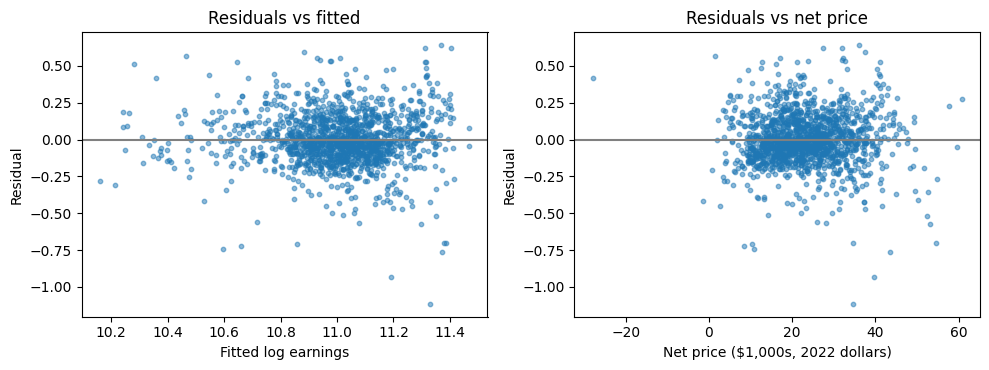

In [28]:
# constant-variance check
bp_p = het_breuschpagan(m2.resid, m2.model.exog)[1]
print(f"Breusch-Pagan p = {bp_p:.4f}")

# Robust SEs
f2 = "log_earn ~ net_price_k + adm_pct + pell_pct + C(control, Treatment('Public'))"
m2r = smf.ols(f2, sample).fit(cov_type="HC3")
print(pd.DataFrame({"classical SE": m2.bse, "robust SE": m2r.bse}).round(4))

# Variance inflation factors
X = m2.model.exog
print("VIF:", {n: round(variance_inflation_factor(X, i), 2)
               for i, n in enumerate(m2.model.exog_names) if n != "Intercept"})

# largest cook's distance
cooks = pd.Series(m2.get_influence().cooks_distance[0], index=sample["INSTNM"].values)
print("Largest Cook's distance:"); print(cooks.nlargest(3).round(3).to_string())

# will the main coefficient survive without most influential schools
top3 = sample.index[np.argsort(-cooks.values)[:3]]
m2_drop = smf.ols(f2, sample.drop(top3)).fit()
print("Net price coef: all schools", round(m2.params["net_price_k"], 4),
      "| without top 3:", round(m2_drop.params["net_price_k"], 4))

Breusch-Pagan p = 0.0000
                                                    classical SE  robust SE
Intercept                                                 0.0276     0.0367
C(control, Treatment('Public'))[T.Private for-p...        0.0368     0.0544
C(control, Treatment('Public'))[T.Private nonpr...        0.0130     0.0147
net_price_k                                               0.0007     0.0011
adm_pct                                                   0.0003     0.0003
pell_pct                                                  0.0003     0.0004
VIF: {"C(control, Treatment('Public'))[T.Private for-profit]": np.float64(1.23), "C(control, Treatment('Public'))[T.Private nonprofit]": np.float64(1.72), 'net_price_k': np.float64(2.12), 'adm_pct': np.float64(1.02), 'pell_pct': np.float64(1.46)}
Largest Cook's distance:
Chamberlain University-Florida     0.069
Chamberlain University-Illinois    0.059
Chamberlain University-Ohio        0.057
Net price coef: all schools 0.005 | without top 

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [29]:
REPORT_NUMBERS = {
    "Section 1: rows, columns in current Scorecard file": full_df.shape,
    "Section 1: rows in 2010-11 file": historical_df.shape[0],
    "Section 1: current schools matched to 2010-11 file": int(df["in_2010_file"].sum()),
    "Section 1: match rate (%)": round(df["in_2010_file"].mean() * 100, 1),
    "Section 1: suppressed (PS) earnings, full file": int(df["earn_suppressed"].sum()),
    "Section 1: blank earnings, full file": int(df["MD_EARN_WNE_P10"].isna().sum() - df["earn_suppressed"].sum()),
    "Section 1: CPI factor AY2009-10 to 2022 dollars": round(cpi_factor, 3),
    "Section 1: bachelor's-focused in 2010 and in current file": len(bach),
    "Section 1: missing earnings, count and % (bachelor's-focused)": (int(bach["MD_EARN_WNE_P10"].isna().sum()), round(bach["MD_EARN_WNE_P10"].isna().mean() * 100, 1)),
    "Section 1: missing net price, count and %": (int(bach["net_price_2010"].isna().sum()), round(bach["net_price_2010"].isna().mean() * 100, 1)),
    "Section 1: missing Pell share, count and %": (int(bach["PCTPELL_2010"].isna().sum()), round(bach["PCTPELL_2010"].isna().mean() * 100, 1)),
    "Section 1: missing admission rate, count and %": (int(bach["ADM_RATE_2010"].isna().sum()), round(bach["ADM_RATE_2010"].isna().mean() * 100, 1)),
    "Section 1: missing SAT, count and %": (int(bach["SAT_AVG_2010"].isna().sum()), round(bach["SAT_AVG_2010"].isna().mean() * 100, 1)),
    "Table 1: no match in 2010-11 file on UNITID": int((~df["in_2010_file"]).sum()),
    "Table 1: in both files but not bachelor's-focused in 2010": int(df["in_2010_file"].sum()) - len(bach),
    "Table 1: no earnings": int(bach["MD_EARN_WNE_P10"].isna().sum()),
    "Table 1: no net price (after earnings step)": int(bach.dropna(subset=["MD_EARN_WNE_P10"])["net_price_2010"].isna().sum()),
    "Table 1: no Pell share (after earnings and net price)": int(bach.dropna(subset=["MD_EARN_WNE_P10", "net_price_2010"])["PCTPELL_2010"].isna().sum()),
    "Table 1: no admission rate (after the steps above)": int(bach.dropna(subset=["MD_EARN_WNE_P10", "net_price_2010", "PCTPELL_2010"])["ADM_RATE_2010"].isna().sum()),
    "Table 1: schools in the sample": len(sample),
    "Table 2: summary statistics (mean, median, std, min, max, N)": table1.round(1).to_dict("index"),
    "Section 2: earnings mean ($)": round(sample["MD_EARN_WNE_P10"].mean()),
    "Section 2: earnings median ($)": round(sample["MD_EARN_WNE_P10"].median()),
    "Section 2: earnings skew, raw": round(sample["MD_EARN_WNE_P10"].skew(), 2),
    "Section 2: earnings skew, log": round(sample["log_earn"].skew(), 2),
    "Section 2: five highest earnings ($k)": sample.nlargest(5, "earn_k")["earn_k"].round(1).tolist(),
    "Section 2: admission rates of the five highest earners (%)": sample.nlargest(5, "earn_k")["adm_pct"].round(1).tolist(),
    "Section 2: corr net price vs log earnings": round(sample["net_price_k"].corr(sample["log_earn"]), 2),
    "Section 2: corr net price vs log earnings, by sector": {k: round(g["net_price_k"].corr(g["log_earn"]), 2) for k, g in sample.groupby("control")},
    "Section 2: corr admission rate vs net price": round(sample["adm_pct"].corr(sample["net_price_k"]), 2),
    "Section 2: corr admission rate vs log earnings": round(sample["adm_pct"].corr(sample["log_earn"]), 2),
    "Section 2: 25th percentile admission rate (%)": round(sample["adm_pct"].quantile(0.25), 1),
    "Section 2: median earnings by admission quartile ($k)": sample.groupby("adm_group", observed=True)["earn_k"].median().round(1).to_dict(),
    "Section 2: earnings 25th and 75th percentile by admission quartile ($k)": sample.groupby("adm_group", observed=True)["earn_k"].quantile([0.25, 0.75]).unstack().round(1).to_dict("index"),
    "Section 2: median net price by admission quartile ($k)": sample.groupby("adm_group", observed=True)["net_price_k"].median().round(1).to_dict(),
    "Section 3: net price coefficient, simple model": round(m1.params["net_price_k"], 4),
    "Section 3: % earnings per +$1,000, simple model": round(100 * (np.exp(m1.params["net_price_k"]) - 1), 2),
    "Section 3: net price coefficient, with controls": round(m2.params["net_price_k"], 4),
    "Section 3: % earnings per +$1,000, with controls": round(100 * (np.exp(m2.params["net_price_k"]) - 1), 2),
    "Section 3: share of the simple coefficient lost with controls (%)": round(100 * (1 - m2.params["net_price_k"] / m1.params["net_price_k"])),
    "Section 3: $ at median earnings per +$1,000": round(sample["MD_EARN_WNE_P10"].median() * (np.exp(m2.params["net_price_k"]) - 1)),
    "Section 3: HC3 95% CI low, high (%)": (round(100 * (np.exp(m2r.conf_int().loc["net_price_k"].iloc[0]) - 1), 2), round(100 * (np.exp(m2r.conf_int().loc["net_price_k"].iloc[1]) - 1), 2)),
    "Section 3: classical 95% CI low, high (%)": (round(100 * (np.exp(m2.conf_int().loc["net_price_k"].iloc[0]) - 1), 2), round(100 * (np.exp(m2.conf_int().loc["net_price_k"].iloc[1]) - 1), 2)),
    "Section 3: Pell share, % per +10 percentage points": round(100 * (np.exp(10 * m2.params["pell_pct"]) - 1), 2),
    "Section 3: Pell share p-value": float(m2.pvalues["pell_pct"]),
    "Section 3: admission rate coefficient and % per +10 percentage points": (round(m2.params["adm_pct"], 4), round(100 * (np.exp(10 * m2.params["adm_pct"]) - 1), 2)),
    "Section 3: private nonprofit coefficient, classical SE, % vs public": (round(m2.params["C(control, Treatment('Public'))[T.Private nonprofit]"], 4), round(m2.bse["C(control, Treatment('Public'))[T.Private nonprofit]"], 4), round(100 * (np.exp(m2.params["C(control, Treatment('Public'))[T.Private nonprofit]"]) - 1), 2)),
    "Section 3: private for-profit coefficient, classical SE, robust SE, % vs public": (round(m2.params["C(control, Treatment('Public'))[T.Private for-profit]"], 4), round(m2.bse["C(control, Treatment('Public'))[T.Private for-profit]"], 4), round(m2r.bse["C(control, Treatment('Public'))[T.Private for-profit]"], 4), round(100 * (np.exp(m2.params["C(control, Treatment('Public'))[T.Private for-profit]"]) - 1), 2)),
    "Section 3: R2 simple, with controls": (round(m1.rsquared, 3), round(m2.rsquared, 3)),
    "Section 3: N": int(m2.nobs),
    "Section 4: Breusch-Pagan p": round(bp_p, 4),
    "Section 4: classical vs HC3 standard errors": pd.DataFrame({"classical": m2.bse, "HC3": m2r.bse}).round(4).to_dict(),
    "Section 4: HC3 SE on net price vs classical (% larger)": round(100 * (m2r.bse["net_price_k"] / m2.bse["net_price_k"] - 1)),
    "Section 4: residual min and max": (round(m2.resid.min(), 2), round(m2.resid.max(), 2)),
    "Section 4: residuals below -0.7": int((m2.resid < -0.7).sum()),
    "Section 4: variance inflation factors": {n: round(variance_inflation_factor(X, i), 2) for i, n in enumerate(m2.model.exog_names) if n != "Intercept"},
    "Section 4: three largest Cook's distances": cooks.nlargest(3).round(3).to_dict(),
    "Section 4: net price coefficient without top 3 influential schools": round(m2_drop.params["net_price_k"], 5),
    "Appendix: regression table": table2.to_dict(),
}
for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: rows, columns in current Scorecard file: (6278, 3379)
Section 1: rows in 2010-11 file: 7470
Section 1: current schools matched to 2010-11 file: 4765
Section 1: match rate (%): 75.9
Section 1: suppressed (PS) earnings, full file: 623
Section 1: blank earnings, full file: 362
Section 1: CPI factor AY2009-10 to 2022 dollars: 1.35
Section 1: bachelor's-focused in 2010 and in current file: 1727
Section 1: missing earnings, count and % (bachelor's-focused): (53, np.float64(3.1))
Section 1: missing net price, count and %: (111, np.float64(6.4))
Section 1: missing Pell share, count and %: (14, np.float64(0.8))
Section 1: missing admission rate, count and %: (258, np.float64(14.9))
Section 1: missing SAT, count and %: (457, np.float64(26.5))
Table 1: no match in 2010-11 file on UNITID: 1513
Table 1: in both files but not bachelor's-focused in 2010: 3038
Table 1: no earnings: 53
Table 1: no net price (after earnings step): 89
Table 1: no Pell share (after earnings and net price): 0
Ta

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.